<a href="https://colab.research.google.com/github/goswamijenya-bit/Applied-Data-Science-1/blob/main/Data%20Handling%20and%20Visualisation%20Assignment%203.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd

# NASA Exoplanet Archive: Planetary Systems Composite Parameters table (pscomppars),
# one row per confirmed planet, downloaded as CSV through the archive's TAP service
URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync?query=select+*+from+pscomppars&format=csv"

planets = pd.read_csv(URL)

# Save a copy: the assignment requires the data file to be submitted too,
# and the archive updates over time, so your copy keeps your results fixed
planets.to_csv("pscomppars_exoplanets.csv", index=False)

print(planets.shape)     # (rows, columns)
planets.head()

(6451, 703)


,systemid,sy_name,objectid,pl_name,pl_letter,hostid,hostname,hd_name,hip_name,tic_id,...,pl_tsm_solnid,pl_tsmstr,pl_tsmlim,pl_esm,pl_esmerr1,pl_esmerr2,pl_esm_reflink,pl_esm_solnid,pl_esmstr,pl_esmlim
0,1.55834,55 Cnc,3.10921,55 Cnc b,b,2.55834,55 Cnc,HD 75732,HIP 43587,TIC 332064670,...,NaN,NaN,NaN,460.0,NaN,NaN,<a refstr=CALCULATED_VALUE href=/docs/pscp_cal...,NaN,460.0,0.0
1,1.55834,55 Cnc,3.10922,55 Cnc c,c,2.55834,55 Cnc,HD 75732,HIP 43587,TIC 332064670,...,NaN,NaN,NaN,59.9,NaN,NaN,<a refstr=CALCULATED_VALUE href=/docs/pscp_cal...,NaN,60.0,0.0
2,1.55834,55 Cnc,3.10923,55 Cnc d,d,2.55834,55 Cnc,HD 75732,HIP 43587,TIC 332064670,...,NaN,NaN,NaN,0.0,NaN,NaN,<a refstr=CALCULATED_VALUE href=/docs/pscp_cal...,NaN,0.0,0.0
3,1.55834,55 Cnc,3.10924,55 Cnc e,e,2.55834,55 Cnc,HD 75732,HIP 43587,TIC 332064670,...,NaN,255.0,0.0,70.1,NaN,NaN,<a refstr=CALCULATED_VALUE href=/docs/pscp_cal...,NaN,70.0,0.0
4,1.55834,55 Cnc,3.10925,55 Cnc f,f,2.55834,55 Cnc,HD 75732,HIP 43587,TIC 332064670,...,NaN,NaN,NaN,2.8,NaN,NaN,<a refstr=CALCULATED_VALUE href=/docs/pscp_cal...,NaN,3.0,0.0


In [3]:
# Pick the columns we need and give them readable names
rename_map = {
    "pl_name": "planet",
    "hostname": "star",
    "discoverymethod": "method",
    "disc_year": "year",
    "disc_facility": "facility",
    "disc_locale": "locale",
    "pl_rade": "radius_earth",
    "pl_bmasse": "mass_earth",
    "pl_orbper": "year_length_days",
    "pl_orbsmax": "orbit_au",
    "pl_eqt": "temp_k",
    "pl_insol": "starlight_earth",
    "st_teff": "star_temp_k",
    "st_mass": "star_mass_sun",
    "sy_dist": "distance_pc",
}

# Keep only columns that exist in the table (protects against a name change)
keep = [c for c in rename_map if c in planets.columns]
df = planets[keep].rename(columns=rename_map)

print(df.shape)
print()

# How many values are missing in each column (as a percentage)?
missing_pct = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print(missing_pct)

df.head()

(6451, 15)

starlight_earth     9.2
temp_k              8.4
orbit_au            7.7
year_length_days    5.5
star_temp_k         4.8
radius_earth        0.8
mass_earth          0.5
distance_pc         0.4
star_mass_sun       0.1
locale              0.0
facility            0.0
planet              0.0
star                0.0
year                0.0
method              0.0
dtype: float64


,planet,star,method,year,facility,locale,radius_earth,mass_earth,year_length_days,orbit_au,temp_k,starlight_earth,star_temp_k,star_mass_sun,distance_pc
0,55 Cnc b,55 Cnc,Radial Velocity,1996,Lick Observatory,Ground,13.900,263.9785,14.651552,0.11800,700.00,45.6336,5198.0,1.015,12.5855
1,55 Cnc c,55 Cnc,Radial Velocity,2004,McDonald Observatory,Ground,8.510,54.4738,44.393600,0.24700,499.27,10.4149,5198.0,1.015,12.5855
2,55 Cnc d,55 Cnc,Radial Velocity,2002,Lick Observatory,Ground,13.000,1232.4930,4799.000000,5.60000,104.85,0.0203,5198.0,1.015,12.5855
3,55 Cnc e,55 Cnc,Radial Velocity,2004,McDonald Observatory,Ground,1.875,7.9900,0.736547,0.01544,1958.00,2657.8322,5172.0,0.905,12.5855
4,55 Cnc f,55 Cnc,Radial Velocity,2007,Multiple Observatories,Ground,7.590,44.8120,260.580000,0.80200,277.07,0.9879,5198.0,1.015,12.5855


In [4]:
# 1. Duplicates: each planet should appear only once
print("Duplicate planet names:", df["planet"].duplicated().sum())

# 2. Categories: how were planets found, and from where?
print("\nDiscovery methods:")
print(df["method"].value_counts())
print("\nGround or space:")
print(df["locale"].value_counts())

# 3. Time span of discoveries
print("\nFirst and last discovery year:", df["year"].min(), "to", df["year"].max())

# 4. Number summary (.T turns columns into rows so it is easier to read)
num_cols = ["radius_earth", "mass_earth", "year_length_days", "orbit_au",
            "temp_k", "starlight_earth", "star_temp_k", "star_mass_sun", "distance_pc"]
print("\nNumber summary:")
print(df[num_cols].describe().round(2).T)

# 5. Flag values that the archive CALCULATED instead of measuring.
#    The reference column contains the text CALCULATED_VALUE for those.
for new_col, ref_col, value_col in [("radius_calculated", "pl_rade_reflink", "radius_earth"),
                                    ("mass_calculated", "pl_bmasse_reflink", "mass_earth")]:
    if ref_col in planets.columns:
        df[new_col] = planets[ref_col].astype(str).str.contains("CALCULATED_VALUE", na=False)
        share = df.loc[df[value_col].notna(), new_col].mean() * 100
        print(f"\n{value_col}: {share:.1f}% of values are calculated, not measured")

Duplicate planet names: 0

Discovery methods:
method
Transit                          4785
Radial Velocity                  1204
Microlensing                      292
Imaging                            98
Transit Timing Variations          29
Eclipse Timing Variations          17
Orbital Brightness Modulation       9
Pulsar Timing                       8
Astrometry                          6
Pulsation Timing Variations         2
Disk Kinematics                     1
Name: count, dtype: int64

Ground or space:
locale
Space               4420
Ground              1993
Multiple Locales      36
ground                 2
Name: count, dtype: int64

First and last discovery year: 1992 to 2026

Number summary:
                   count      mean         std     min      25%      50%  \
radius_earth      6401.0      5.84        5.40    0.31     1.85     2.86   
mass_earth        6421.0    402.69     1141.95    0.02     4.35     9.32   
year_length_days  6097.0  70215.80  5150759.02    0.09     4.2

In [5]:
# 1. Fix inconsistent labels: "ground" and "Ground" are the same thing
df["locale"] = df["locale"].str.title()

# 2. Group the 11 discovery methods: keep the 4 main ones, merge the 7 small ones as "Other"
main_methods = ["Transit", "Radial Velocity", "Microlensing", "Imaging"]
df["method_group"] = df["method"].where(df["method"].isin(main_methods), "Other")

# 3. Discovery decade (for the heatmap and the timeline)
df["decade"] = (df["year"] // 10 * 10).astype(int)

# 4. Flag the incomplete final year so it is not mistaken for a real drop
latest_year = df["year"].max()
df["partial_year"] = df["year"] == latest_year

# 5. Planet size classes (rough groupings by radius in Earth radii; cut-offs are my choice)
bins = [0, 1.25, 2, 6, float("inf")]
labels = ["Earth-sized (<1.25)", "Super-Earth (1.25-2)", "Neptune-sized (2-6)", "Jupiter-sized (6+)"]
df["size_class"] = pd.cut(df["radius_earth"], bins=bins, labels=labels, right=False)

# ---- Checks ----
print(df["locale"].value_counts(), "\n")
print((df["method_group"].value_counts(normalize=True) * 100).round(1), "\n")
print(df["size_class"].value_counts(dropna=False), "\n")
print("Latest year in the data:", latest_year,
      "| planets in that year:", df["partial_year"].sum(), "\n")

# The most extreme planets, so we can explain them in the report
print(df.nlargest(3, "year_length_days")[["planet", "method", "year_length_days", "orbit_au"]], "\n")
print(df.nlargest(3, "mass_earth")[["planet", "method", "mass_earth", "radius_earth"]])

locale
Space               4420
Ground              1995
Multiple Locales      36
Name: count, dtype: int64 

method_group
Transit            74.2
Radial Velocity    18.7
Microlensing        4.5
Imaging             1.5
Other               1.1
Name: proportion, dtype: float64 

size_class
Neptune-sized (2-6)     2442
Jupiter-sized (6+)      2164
Super-Earth (1.25-2)    1212
Earth-sized (<1.25)      583
NaN                       50
Name: count, dtype: int64 

Latest year in the data: 2026 | planets in that year: 361 

                planet   method  year_length_days  orbit_au
6111      COCONUTS-2 b  Imaging       402000000.0    7506.0
5593  CFHTWIR-Oph 98 b  Imaging         8040000.0     200.0
1374          Oph 11 b  Imaging         7300000.0     243.0 

                         planet   method    mass_earth  radius_earth
3373                Kepler-80 f  Transit  12651.500000          1.21
1297  2MASS J22501512+2325342 b  Imaging   9534.852210         11.90
4856                Luhman 16

In [6]:
# 1. Relative density compared with Earth (mass / radius^3, Earth = 1).
#    Large values for SMALL planets are physically impossible -> data inconsistency.
df["rel_density"] = df["mass_earth"] / df["radius_earth"] ** 3

print("Top 8 planets by relative density:")
cols = ["planet", "method", "mass_earth", "radius_earth", "rel_density", "mass_calculated", "radius_calculated"]
print(df.nlargest(8, "rel_density")[cols].round(2).to_string(), "\n")

# 2. Is there a spike of identical radius values?
print("Most common radius values (Earth radii):")
print(df["radius_earth"].round(2).value_counts().head(8), "\n")

# 3. How much of each size class is calculated rather than measured?
share_calc = (df.groupby("size_class", observed=True)["radius_calculated"].mean() * 100).round(1)
print("Percent of radii that are calculated, by size class:")
print(share_calc, "\n")

# 4. Same check by discovery method
print("Percent of radii that are calculated, by method group:")
print((df.groupby("method_group")["radius_calculated"].mean() * 100).round(1))

Top 8 planets by relative density:
            planet   method  mass_earth  radius_earth  rel_density  mass_calculated  radius_calculated
3373   Kepler-80 f  Transit    12651.50          1.21      7141.44            False              False
1814   Kepler-32 f  Transit     1862.11          0.82      3377.25            False              False
2175  Kepler-324 b  Transit     2414.40          1.14      1629.65            False              False
4235   KOI-4777.01  Transit       99.20          0.51       747.83            False              False
3502  Kepler-238 b  Transit     3305.02          1.73       638.32            False              False
5231      K2-137 b  Transit      158.92          0.64       606.21            False              False
4798  Kepler-245 e  Transit     1806.36          1.75       337.05            False              False
2754   KOI-2513.01  Transit     7310.05          2.80       332.20            False              False 

Most common radius values (Earth rad

In [7]:
# 1. Do the impossible-density planets have mass or radius LIMITS (not real measurements)?
#    The archive's limit columns: 1 = upper limit, -1 = lower limit, 0 = a normal measurement
limit_cols = ["pl_bmasselim", "pl_radelim"]
top = df.nlargest(8, "rel_density").index
print("Limit flags for the 8 impossible-density planets:")
print(planets.loc[top, ["pl_name"] + limit_cols].to_string(), "\n")

print("Mass limit flag across ALL planets:")
print(planets["pl_bmasselim"].value_counts(dropna=False), "\n")

# 2. Mass: how much is calculated, by method?
print("Percent of masses that are calculated, by method group:")
print((df.groupby("method_group")["mass_calculated"].mean() * 100).round(1), "\n")

# 3. Build "measured only" columns: calculated values and limit values become NaN
df["radius_measured"] = df["radius_earth"].where(~df["radius_calculated"] & (planets["pl_radelim"].fillna(0) == 0))
df["mass_measured"] = df["mass_earth"].where(~df["mass_calculated"] & (planets["pl_bmasselim"].fillna(0) == 0))

# 4. Flag physically implausible mass/radius pairs (relative density above 3 x Earth)
df["implausible"] = df["rel_density"] > 3
print("Planets flagged as implausible:", df["implausible"].sum(), "\n")

# 5. How much data survives?
print("Planets with a MEASURED radius:", df["radius_measured"].notna().sum())
print("Planets with a MEASURED mass:  ", df["mass_measured"].notna().sum())
print("Planets with BOTH measured:    ", (df["radius_measured"].notna() & df["mass_measured"].notna()).sum())
print("\nMeasured radius by method:"); print(df.groupby("method_group")["radius_measured"].count())
print("\nMeasured mass by method:");   print(df.groupby("method_group")["mass_measured"].count())

Limit flags for the 8 impossible-density planets:
           pl_name  pl_bmasselim  pl_radelim
3373   Kepler-80 f           1.0         0.0
1814   Kepler-32 f           1.0         0.0
2175  Kepler-324 b           1.0         0.0
4235   KOI-4777.01           1.0         0.0
3502  Kepler-238 b           1.0         0.0
5231      K2-137 b           1.0         0.0
4798  Kepler-245 e           1.0         0.0
2754   KOI-2513.01           0.0         0.0 

Mass limit flag across ALL planets:
pl_bmasselim
 0.0    6182
 1.0     226
 NaN      30
-1.0      13
Name: count, dtype: int64 

Percent of masses that are calculated, by method group:
method_group
Imaging             0.0
Microlensing        0.0
Other               0.0
Radial Velocity     0.0
Transit            63.4
Name: mass_calculated, dtype: float64 

Planets flagged as implausible: 217 

Planets with a MEASURED radius: 4857
Planets with a MEASURED mass:   3147
Planets with BOTH measured:     1605

Measured radius by method:
method_g

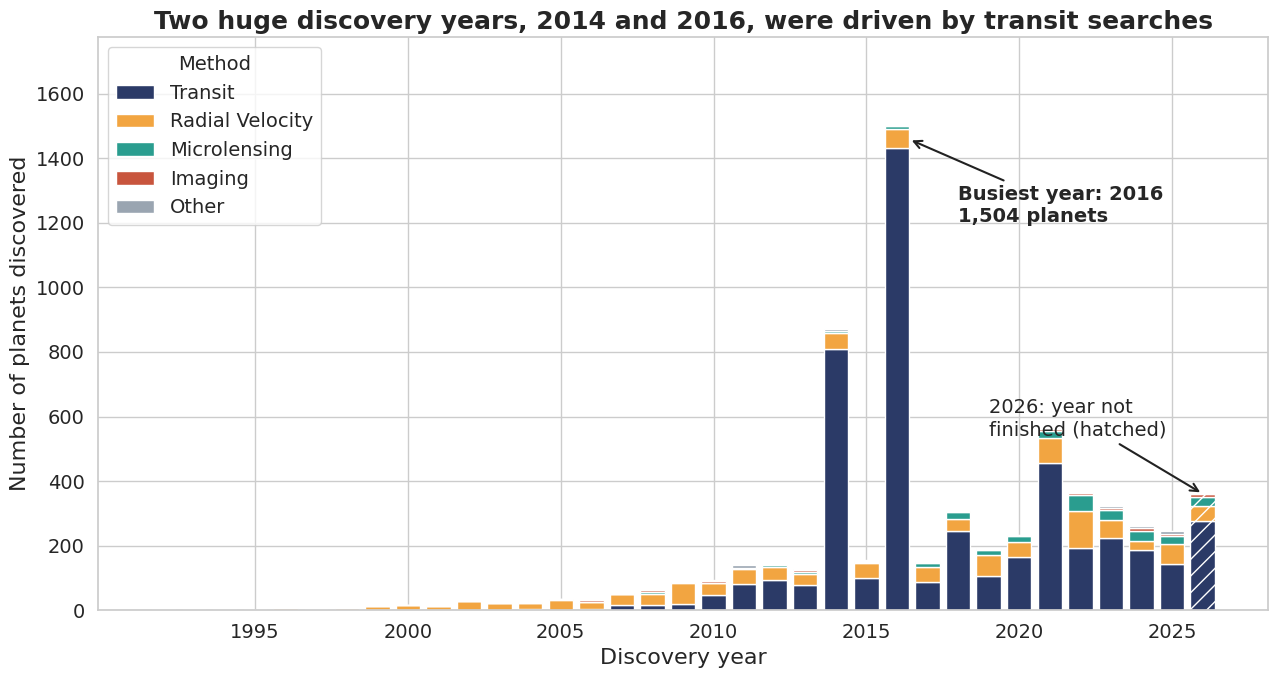

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ---------- Global style: every font is 14 or larger ----------
sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "font.size": 14, "axes.titlesize": 18, "axes.labelsize": 16,
    "xtick.labelsize": 14, "ytick.labelsize": 14,
    "legend.fontsize": 14, "legend.title_fontsize": 14,
    "axes.titleweight": "bold", "savefig.bbox": "tight",
})

# One fixed colour per discovery method, reused in every chart
METHOD_ORDER = ["Transit", "Radial Velocity", "Microlensing", "Imaging", "Other"]
METHOD_COLOURS = {"Transit": "#2B3A67", "Radial Velocity": "#F2A541",
                  "Microlensing": "#2A9D8F", "Imaging": "#C8553D", "Other": "#9AA5B1"}


def plot_discoveries_per_year(data):
    """Stacked bar chart: number of planets discovered each year, split by method."""
    # Count planets for every year and method (years with none become 0)
    counts = (data.groupby(["year", "method_group"]).size()
                  .unstack(fill_value=0)
                  .reindex(columns=METHOD_ORDER, fill_value=0))
    counts = counts.reindex(range(data["year"].min(), data["year"].max() + 1), fill_value=0)
    totals = counts.sum(axis=1)
    latest = counts.index.max()

    fig, ax = plt.subplots(figsize=(13, 7))
    bottom = np.zeros(len(counts))
    for method in METHOD_ORDER:
        ax.bar(counts.index, counts[method], bottom=bottom, width=0.8,
               color=METHOD_COLOURS[method], label=method)
        bottom += counts[method].values

    # Hatch the last bar: that year is not finished yet
    for container in ax.containers:
        for patch in container:
            if round(patch.get_x() + patch.get_width() / 2) == latest:
                patch.set_hatch("//")
                patch.set_edgecolor("white")

    # Annotation 1: the busiest year, labelled in the empty space to the right of the peak
    peak_year, peak_total = totals.idxmax(), totals.max()
    ax.annotate(f"Busiest year: {peak_year}\n{peak_total:,} planets",
                xy=(peak_year + 0.4, peak_total * 0.97), xytext=(peak_year + 2, peak_total * 0.80),
                fontsize=14, fontweight="bold",
                arrowprops=dict(arrowstyle="->", color="#222222", lw=1.5))

    # Annotation 2: the current year is incomplete
    ax.annotate(f"{latest}: year not\nfinished (hatched)",
                xy=(latest, totals[latest]), xytext=(latest - 7, totals[latest] + peak_total * 0.12),
                fontsize=14, arrowprops=dict(arrowstyle="->", color="#222222", lw=1.5))

    ax.set_title("Two huge discovery years, 2014 and 2016, were driven by transit searches")
    ax.set_xlabel("Discovery year")
    ax.set_ylabel("Number of planets discovered")
    ax.set_xticks(range(1995, latest + 1, 5))
    ax.set_ylim(0, peak_total * 1.18)
    ax.legend(title="Method", loc="upper left", frameon=True)
    plt.tight_layout()
    plt.show()


plot_discoveries_per_year(df)

In [9]:
# Which facilities found the planets in the spike years?
for y in [2014, 2016, 2021]:
    sub = df[df["year"] == y]
    print(f"--- {y}: {len(sub)} planets, {(sub['method'] == 'Transit').mean() * 100:.0f}% found by transit")
    print(sub["facility"].value_counts().head(3), "\n")

# The most productive facilities of all time
print("Top 6 facilities overall:")
print(df["facility"].value_counts().head(6))

--- 2014: 872 planets, 93% found by transit
facility
Kepler                    784
SuperWASP                  20
Multiple Observatories     20
Name: count, dtype: int64 

--- 2016: 1504 planets, 95% found by transit
facility
Kepler                    1276
K2                         103
Multiple Observatories      20
Name: count, dtype: int64 

--- 2021: 564 planets, 81% found by transit
facility
Kepler                                          311
Transiting Exoplanet Survey Satellite (TESS)     77
K2                                               50
Name: count, dtype: int64 

Top 6 facilities overall:
facility
Kepler                                          2787
Transiting Exoplanet Survey Satellite (TESS)    1012
K2                                               550
Multiple Observatories                           355
La Silla Observatory                             311
W. M. Keck Observatory                           194
Name: count, dtype: int64


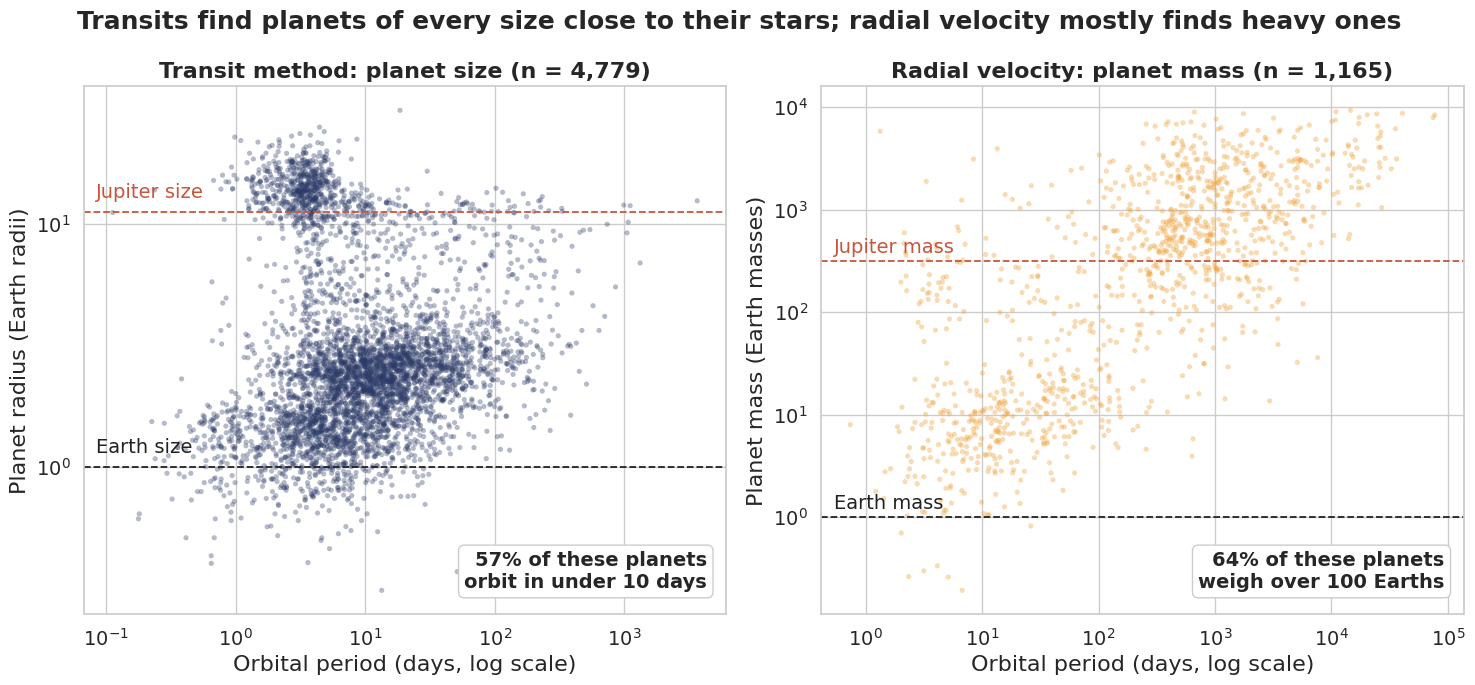

Transit planets with measured radius: 4,779; under 10 days: 57.1%
RV planets with measured mass: 1,165; over 100 Earth masses: 63.6%
Median radius (transit): 2.46 Earth radii
Median mass (RV): 314.7 Earth masses
Median period (transit): 8.0 days; median period (RV): 321.8 days


In [10]:
def plot_period_vs_size(data):
    """Two-panel scatter (log-log): measured radius of transit planets (left)
    and measured mass of radial-velocity planets (right), against orbital period."""
    # Keep only measured values (calculated values and limits were removed earlier)
    tr = data[(data["method"] == "Transit") & data["radius_measured"].notna()
              & (data["year_length_days"] > 0)]
    rv = data[(data["method"] == "Radial Velocity") & data["mass_measured"].notna()
              & (data["year_length_days"] > 0)]

    # x = fraction of the axis width, y = data value, so labels never fall outside the panel
    def label(ax, y, text, colour="#222222"):
        ax.text(0.02, y * 1.1, text, transform=ax.get_yaxis_transform(),
                fontsize=14, color=colour, va="bottom")

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7))

    # ----- Left panel: transit planets, radius -----
    ax1.scatter(tr["year_length_days"], tr["radius_measured"], s=14, alpha=0.35,
                color=METHOD_COLOURS["Transit"], edgecolors="none")
    ax1.axhline(1, color="#222222", ls="--", lw=1.3)
    label(ax1, 1, "Earth size")
    ax1.axhline(11.2, color="#C8553D", ls="--", lw=1.3)
    label(ax1, 11.2, "Jupiter size", "#C8553D")
    short_tr = (tr["year_length_days"] < 10).mean() * 100          # computed from the data
    ax1.text(0.97, 0.05, f"{short_tr:.0f}% of these planets\norbit in under 10 days",
             transform=ax1.transAxes, ha="right", fontsize=14, fontweight="bold",
             bbox=dict(facecolor="white", edgecolor="#CCCCCC", boxstyle="round"))
    ax1.set_title(f"Transit method: planet size (n = {len(tr):,})", fontsize=16)
    ax1.set_ylabel("Planet radius (Earth radii)")

    # ----- Right panel: radial-velocity planets, mass -----
    ax2.scatter(rv["year_length_days"], rv["mass_measured"], s=14, alpha=0.4,
                color=METHOD_COLOURS["Radial Velocity"], edgecolors="none")
    ax2.axhline(1, color="#222222", ls="--", lw=1.3)
    label(ax2, 1, "Earth mass")
    ax2.axhline(317.8, color="#C8553D", ls="--", lw=1.3)
    label(ax2, 317.8, "Jupiter mass", "#C8553D")
    heavy_rv = (rv["mass_measured"] > 100).mean() * 100
    ax2.text(0.97, 0.05, f"{heavy_rv:.0f}% of these planets\nweigh over 100 Earths",
             transform=ax2.transAxes, ha="right", fontsize=14, fontweight="bold",
             bbox=dict(facecolor="white", edgecolor="#CCCCCC", boxstyle="round"))
    ax2.set_title(f"Radial velocity: planet mass (n = {len(rv):,})", fontsize=16)
    ax2.set_ylabel("Planet mass (Earth masses)")

    # Settings shared by both panels
    for ax in (ax1, ax2):
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Orbital period (days, log scale)")

    fig.suptitle("Transits find planets of every size close to their stars; "
                 "radial velocity mostly finds heavy ones", fontsize=18, fontweight="bold")
    plt.tight_layout()
    plt.show()

    # Print the numbers used in the annotations so we can quote them in the report
    print(f"Transit planets with measured radius: {len(tr):,}; under 10 days: {short_tr:.1f}%")
    print(f"RV planets with measured mass: {len(rv):,}; over 100 Earth masses: {heavy_rv:.1f}%")
    print(f"Median radius (transit): {tr['radius_measured'].median():.2f} Earth radii")
    print(f"Median mass (RV): {rv['mass_measured'].median():.1f} Earth masses")
    print(f"Median period (transit): {tr['year_length_days'].median():.1f} days; "
          f"median period (RV): {rv['year_length_days'].median():.1f} days")


plot_period_vs_size(df)

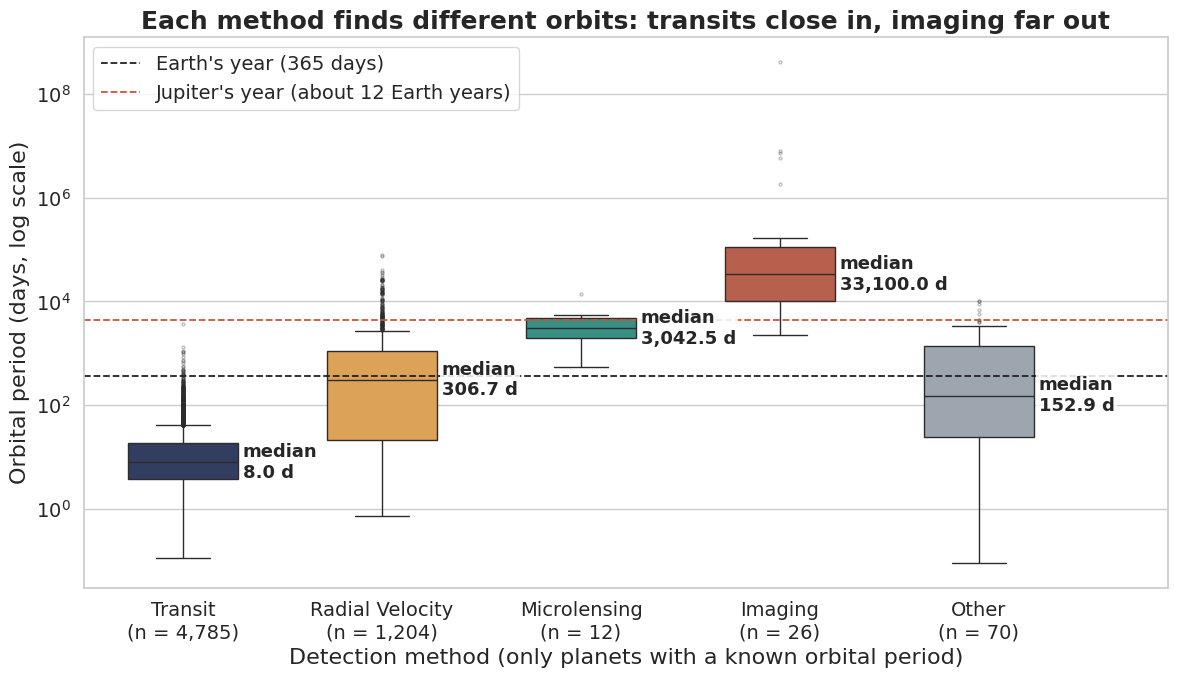

Planets with a known period / all planets of that method:
  Transit: 4,785 / 4,785
  Radial Velocity: 1,204 / 1,204
  Microlensing: 12 / 292
  Imaging: 26 / 98
  Other: 70 / 72

                  count        mean         std     min      25%      50%  \
method_group                                                                
Transit          4785.0        23.3        78.9     0.1      3.8      8.0   
Radial Velocity  1204.0      1759.7      5197.7     0.7     21.9    306.7   
Microlensing       12.0      3971.4      3570.5   550.0   1932.1   3042.5   
Imaging            26.0  16374445.7  78686125.8  2290.0  10303.1  33100.0   
Other              70.0      1318.9      2374.7     0.1     24.8    152.9   

                      75%          max  
method_group                            
Transit              18.8       3650.0  
Radial Velocity    1123.4      77114.1  
Microlensing       4756.9      14200.0  
Imaging          113775.0  402000000.0  
Other              1387.5      10220

In [11]:
def plot_period_by_method(data):
    """Box plot (log scale): orbital period of planets for each detection method."""
    d = data[data["year_length_days"] > 0].copy()

    # Put the number of planets in each x label so small groups are visible
    counts = d["method_group"].value_counts()
    order = [m for m in METHOD_ORDER if m in counts.index]
    labels = [f"{m}\n(n = {counts[m]:,})" for m in order]

    fig, ax = plt.subplots(figsize=(12, 7))
    sns.boxplot(data=d, x="method_group", y="year_length_days", order=order,
                hue="method_group", palette=METHOD_COLOURS, legend=False,
                width=0.55, fliersize=2, flierprops=dict(alpha=0.3), ax=ax)

    # Label each box with its median (computed from the data), on a white background
    medians = d.groupby("method_group")["year_length_days"].median()
    for i, m in enumerate(order):
        ax.text(i + 0.30, medians[m], f"median\n{medians[m]:,.1f} d",
                fontsize=13, fontweight="bold", va="center",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))

    # Reference lines, explained in a legend (keeps labels off the boxes)
    ax.axhline(365, color="#222222", ls="--", lw=1.3, label="Earth's year (365 days)")
    ax.axhline(4333, color="#C8553D", ls="--", lw=1.3, label="Jupiter's year (about 12 Earth years)")

    ax.set_yscale("log")
    ax.set_xlim(-0.5, 4.95)                      # extra room on the right for the median labels
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(labels)
    ax.set_xlabel("Detection method (only planets with a known orbital period)")
    ax.set_ylabel("Orbital period (days, log scale)")
    ax.set_title("Each method finds different orbits: transits close in, imaging far out")
    ax.legend(loc="upper left", frameon=True)
    plt.tight_layout()
    plt.show()

    # Numbers for the report: how many planets of each method have a period?
    total = data["method_group"].value_counts()
    print("Planets with a known period / all planets of that method:")
    for m in order:
        print(f"  {m}: {counts[m]:,} / {total[m]:,}")
    print()
    print(d.groupby("method_group")["year_length_days"].describe().round(1).reindex(order))


plot_period_by_method(df)

           Variable         Unit Planets with data Missing (%) Median  Min     Max Calculated (%)
      Planet radius  Earth radii             6,401         0.8   2.86 0.31   87.21             24
        Planet mass Earth masses             6,421         0.5   9.32 0.02 1.3e+04             47
     Orbital period         days             6,097         5.5  10.64 0.09 4.0e+08              -
         Orbit size           au             5,956         7.7   0.10 0.00 1.9e+04              -
 Planet temperature       kelvin             5,911         8.4    758 1.48   7,778              -
 Starlight received    Earth = 1             5,855         9.2  66.67 0.00 6.4e+05              -
   Star temperature       kelvin             6,144         4.8  5,544  415 5.7e+04              -
          Star mass      Sun = 1             6,442         0.1   0.94 0.01    9.10              -
Distance from Earth      parsecs             6,423         0.4    349 1.30   8,500              -


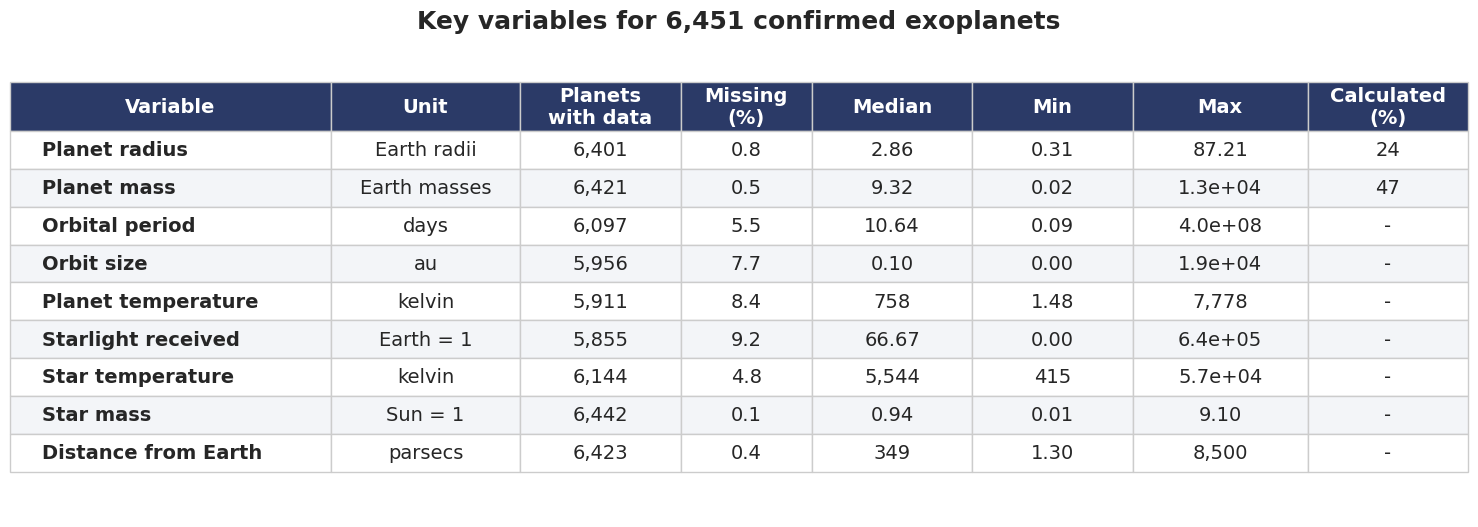

In [12]:
def make_summary_table(data):
    """Summary table of the key variables: how many planets have data, how much is
    missing, typical values, and how much was calculated rather than measured."""
    def fmt(x):
        # Readable numbers whatever the size
        if abs(x) >= 10000:
            return f"{x:.1e}"
        if abs(x) >= 100:
            return f"{x:,.0f}"
        return f"{x:.2f}"

    spec = [("radius_earth", "Planet radius", "Earth radii"),
            ("mass_earth", "Planet mass", "Earth masses"),
            ("year_length_days", "Orbital period", "days"),
            ("orbit_au", "Orbit size", "au"),
            ("temp_k", "Planet temperature", "kelvin"),
            ("starlight_earth", "Starlight received", "Earth = 1"),
            ("star_temp_k", "Star temperature", "kelvin"),
            ("star_mass_sun", "Star mass", "Sun = 1"),
            ("distance_pc", "Distance from Earth", "parsecs")]

    # Share of values that the archive calculated instead of measured (radius and mass only)
    calc = {"radius_earth": data.loc[data["radius_earth"].notna(), "radius_calculated"].mean() * 100,
            "mass_earth": data.loc[data["mass_earth"].notna(), "mass_calculated"].mean() * 100}

    rows = []
    for col, name, unit in spec:
        s = data[col]
        rows.append([name, unit, f"{s.notna().sum():,}", f"{s.isna().mean() * 100:.1f}",
                     fmt(s.median()), fmt(s.min()), fmt(s.max()),
                     f"{calc[col]:.0f}" if col in calc else "-"])

    cols = ["Variable", "Unit", "Planets\nwith data", "Missing\n(%)", "Median", "Min", "Max", "Calculated\n(%)"]
    table = pd.DataFrame(rows, columns=[c.replace("\n", " ") for c in cols])
    print(table.to_string(index=False))

    # ---- Draw the table as an image for the PDF report ----
    fig, ax = plt.subplots(figsize=(15, 5.5))
    ax.axis("off")
    t = ax.table(cellText=rows, colLabels=cols, loc="center", cellLoc="center",
                 colWidths=[0.22, 0.13, 0.11, 0.09, 0.11, 0.11, 0.12, 0.11])
    t.auto_set_font_size(False)
    t.set_fontsize(14)
    t.scale(1, 2.0)
    for (r, c), cell in t.get_celld().items():
        cell.set_edgecolor("#CCCCCC")
        if r == 0:
            cell.set_facecolor("#2B3A67")
            cell.set_text_props(color="white", fontweight="bold")
            cell.set_height(cell.get_height() * 1.3)
        elif r % 2 == 0:
            cell.set_facecolor("#F3F5F8")
        if c == 0 and r > 0:
            cell.set_text_props(ha="left", fontweight="bold")
    ax.set_title(f"Key variables for {len(data):,} confirmed exoplanets", fontsize=18, fontweight="bold")
    plt.tight_layout()
    plt.savefig("summary_table.png", dpi=200, bbox_inches="tight")
    plt.show()
    return table


summary = make_summary_table(df)

# Save the cleaned data file (the brief asks for the data files to be submitted)
df.to_csv("exoplanets_clean.csv", index=False)